In [ ]:
!pip install ai-edge-litert

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.8/21.8 MB 20.4 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
from collections import deque
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
print(tf.__version__)

2.21.0


# DQN Network training and LiteRT export

This notebook contains the scripts to define a simple recommendation system based on the supervised DQN pipeline. A set of classes below provide the abstractions for the DQN network and the Replay Memory for batch training. Instead of relying on classic RL gym environments to define the boundary and reward functions for the model, a custom environment is available to operate on the model from a time series dataset to emulate the interactions of a user with a mobile banking App.  

Implementation inspired and based on the great tutorial from Lukas Schwarz [https://lukasschwarz.de/dqn]


TODO:
1. Evaluate the use of CategoricalCrossentropy as the loss function in the Reinforcement Learning Train_DQN function. CategoricalCrossentropy provides better training results on the supervised training loop.
2. Expand input feature space (is-weekend app-logins-count, location, etc.).
3. Perform hyperparameter tunning for the model and reward function configurations.

Sources:
- https://www.cs.toronto.edu/%7Evmnih/docs/dqn.pdf
- https://builtin.com/artificial-intelligence/double-deep-q-learning
- https://github.com/patrickloeber/snake-ai-pytorch/blob/main/agent.py
- https://www.tensorflow.org/agents/tutorials/0_intro_rl
- https://lukasschwarz.de/dqn
- https://huggingface.co/learn/deep-rl-course/unit2/q-learning
- https://developers.google.com/edge/litert/conversion/tensorflow/build/ondevice_training

### Global constants

In [ ]:
#for reproducibility, keep common random state seed
SEED = 42
rng = np.random.default_rng(SEED)

#Expected data_frame schema
DATA_FRAME_SCHEMA = {
    'date', 'dom', 'user-action', 'session-Id', 'total-balance',
    'account-from', 'main-savings-balance', 'main-savings-status', 'next-action', 'current-state-features',
    'next-state-features'
}

#Model-related parameters
#VOCABULARY_SIZE = 2**16
#EMBEDDING_DIM = 64  # Increased from 16 to 64 to improve model capacity
#TARGET_ACTIONS = 16

#Global variables to keep all user-actions / app-states registered in dataset
non_payment_actions = ['Account_Details', 'Dashboard', 'Transaction_Historical']
payment_actions = []

'''
Lookup tables that provide the range of int required to encode the feature space to feed as inputs to the model
'''

account_status_map = {
    "NEGATIVE": 1,
    "FLAT": 2,
    "POSITIVE": 3
}

unique_user_actions = []
user_actions_map = dict()

unique_accounts = []
accounts_map = dict()

#Model training validation
TEST_PROPORTION = 0.25
TRAIN_SAMPLES = 10000

#The input layer dim
FEATURE_DIM = 6

#The output layer dim
ACTIONS_DIM = 9
UNITS_DIM = 100

#Experience Replay params
BUFFER_SIZE = 20

#Percentage of samples to allocate in x DataFrame with transitions to non-transactional states
NON_TRANSACTIONS_SAMPLE_FACTOR = 1.25

### Helper functions

In [ ]:
def prepare_data(data_frame):
    '''
    Create a feature space from an input DataFrame data_frame.
    data_frame: Pandas DataFrame, a collection with the columns defined in the DATA_FRAME_SCHEMA constant
    # Output Feature schema:
      {current_state, dom, accnt_1, accnt_2, accnt_3, accnt_4, next_state, terminal_state}
    # Feature params:
      current_state: float, a numeric map from the index of an action registered in unique_user_actions
      dom: float, the current day-of-month registered within the range [1, 31]
      next_state: float, the following action-state taken by the user in session. Not required for feeding the
        DQN network but gives info about the reward and loss calculation. A correct assumption about next_state by the model
        will result in a higher reward.
      accnt_{x}: float, a numeric representation of the current status in account x. It maps the changes in amount
        for the account comparing the amounts from the last session according to the values given in the account_status_map enum
    '''
    #reference global variables to make updated parameters available to the model and other entities
    #global payment_actions
    global non_payment_actions
    global unique_user_actions
    global user_actions_map
    global unique_accounts
    global accounts_map
    global ACTIONS_DIM

    # Check column names match exactly
    global DATA_FRAME_SCHEMA
    assert not set(data_frame.columns) ^ DATA_FRAME_SCHEMA, "Columns in data_frame mismatch"

    global SEED

    #Gather all user-actions related to payments
    #payment_actions = np.delete(data_frame['user-action'].unique(), np.isin(data_frame['user-action'].unique(), non_payment_actions))

    #Homologate non-payment-actions to just one tipology 'Dashboard' to reduce the DQN network output dimension and focus on payment-actions inference
    current_action_non_payment_indx = df['user-action'].isin(non_payment_actions)
    next_action_non_payment_indx = df['next-action'].isin(non_payment_actions)
    data_frame.loc[current_action_non_payment_indx, 'user-action'] = 'Dashboard'
    data_frame.loc[next_action_non_payment_indx, 'next-action'] = 'Dashboard'

    #Update user_actions_map dictionary
    unique_user_actions = data_frame['user-action'].unique()
    user_actions_map = dict([(unique_user_actions[indx], indx) for indx in range(unique_user_actions.size)])
    ACTIONS_DIM = unique_user_actions.size

    #Obtain all accounts involved in the transactions
    unique_accounts = data_frame['account-from'].unique()
    accounts_map = dict([(unique_accounts[indx], indx) for indx in range(unique_accounts.size)])

    #Gather all user-actions related to payments
    payment_actions = np.delete(data_frame['user-action'].unique(), np.isin(data_frame['user-action'].unique(), non_payment_actions))

    #Process features set
    #TODO: modify dataset to include more than 1 account and correlate the transactional behaviour to changes in those accounts
    data_frame['current_state'] = data_frame.apply(lambda row: user_actions_map[row['user-action']], axis=1)
    data_frame['next_state'] = data_frame.apply(lambda row: user_actions_map[row['next-action']], axis=1)
    data_frame['accnt_1'] = data_frame.apply(lambda row: account_status_map[row['main-savings-status']], axis=1)
    data_frame['accnt_2'] = data_frame.apply(lambda row: 0, axis=1)
    data_frame['accnt_3'] = data_frame.apply(lambda row: 0, axis=1)
    data_frame['accnt_4'] = data_frame.apply(lambda row: 0, axis=1)
    #Determine the terminal state for the events that correspond to an end of session
    data_frame['shifted-session-Id'] = data_frame['session-Id'].shift(-1) #helper column to compare previous session-Id in lambda fun. below
    #data_frame['terminal_state'] = df.apply(lambda row: 1 if row['next-action'] in payment_actions else 0, axis=1)
    data_frame['terminal_state'] = data_frame.apply(lambda row: 1 if row['session-Id']!=row['shifted-session-Id'] else 0, axis=1)

    #Create distiled data frame with encoded features
    x = data_frame[['current_state', 'dom', 'accnt_1', 'accnt_2', 'accnt_3', 'accnt_4', 'next_state', 'terminal_state', 'session-Id']]
    #x.reset_index(drop=True, inplace=True)

    return x

In [ ]:
def compute_rewards(q_next_states, next_states, reward_weights, has_payments_in_session):
    """
    Optimized reward function calculation using NumPy vectorization.

    Parameters:
    q_next_states (np.array): Predicted actions from the DQN. In this context and environment a predicted action translates directly to a consecuential state of the same typology
    next_states (np.array): Actual next actions from the dataset / environment.
    reward_weights (dict): Weights for each reward type.
    has_payments_in_session (bool): Indicates if there are any payments in the current session.

    Returns:
    rewards: (np.array): Calculated rewards.
    """

    print("foo" in reward_weights.keys())
    # Validate input shapes
    if q_next_states.shape != next_states.shape:
        raise ValueError(f"Shape mismatch: q_current_states {q_next_states.shape} vs next_states {next_states.shape}")

    if "match_transactional_weight" in reward_weights.keys():
        match_transactional_weight = reward_weights["match_transactional_weight"]
    else:
        match_transactional_weight = 3.0

    if "non_match_transactional_weight" in reward_weights.keys():
        non_match_transactional_weight = reward_weights["non_match_transactional_weight"]
    else:
        non_match_transactional_weight = 1.5

    if "match_non_transactional_weight" in reward_weights.keys():
        match_non_transactional_weight = reward_weights["match_non_transactional_weight"]
    else:
        match_non_transactional_weight = 1.0

    if "non_match_weight" in reward_weights.keys():
        non_match_weight = reward_weights["non_match_weight"]
    else:
        non_match_weight = -3.0

    # Pre-calculate ID sets for faster lookup
    # TODO: fix mapping function if more than one non-transactional state is to be considered
    non_pay_ids = np.zeros(1) #np.array([user_actions_map[act] for act in ['Dashboard']])

    # Initialize rewards with non_match_weight values
    rewards = np.full(q_next_states.shape, non_match_weight, dtype=np.float32)

    # Boolean mask for successful predictions
    is_match = (q_next_states == next_states)

    # Identify which predicted actions are non-payment actions
    is_non_pay = np.isin(next_states, non_pay_ids)

    payments_in_session = np.isin(next_states, np.arange(1, 10))

    # Rewards logic:
    # 1. Matching non-payment actions get match_non_transactional_weight value
    rewards[is_match & is_non_pay] = match_non_transactional_weight
    # 2. Matching payment actions get match_transactional_weight (if it matches and ISN'T a non-payment action, it's a payment)
    rewards[is_match & ~is_non_pay] = match_transactional_weight
    # 3. Non-matching payment actions get non_match_transactional_weight if at least one transaction takes place in session (has_payments_in_session=True)
    rewards[~is_match & ~is_non_pay & has_payments_in_session] = non_match_transactional_weight

    # Return rewards
    return rewards

In [ ]:
def train_DQ(data_frame, model, reward_weights, gamma, epsilon, epsilon_decay, batch_size, N_Episodes):
  """
  Train the DQN model using reinforcement learning on user sessions.

  Parameters:
  data_frame (pd.DataFrame): The input dataset containing processed state transitions.
  model (tf.keras.Model): The SignatureRegularizedDQN model to train.
  reward_weights (dict): A dictionary specifying weights for different types of matching or non-matching predictions.
  gamma (float): Discount factor for future rewards.
  epsilon (float): Initial exploration rate for epsilon-greedy action selection.
  epsilon_decay (float): Multiplicative factor to decay exploration rate after each episode.
  batch_size (int): Size of transition batches sampled from ReplayMemory during training.
  N_Episodes (int): Maximum number of episodes (user sessions) to train on.

  Returns:
  cumulative_reward (float): Total reward collected across all episodes.
  episode_reward (list): List of rewards accumulated step-by-step.
  mean_absolute_error (np.array): Average prediction error mapped per episode.
  predictions (list): Historical record of raw target state values.
  """
  #An episode is defined by a user session, i.e. the set of entries in data_frame under the same session-Id
  sessions = data_frame['session-Id'].unique()
  n_sessions = sessions.shape[0]

  #Avoid going above the total number of sessions in dataset and prevent the query of number of episodes
  # above the capacity of the ReplayMemory
  N_Episodes = n_sessions if n_sessions < N_Episodes else N_Episodes
  batch_size = batch_size if batch_size <= BUFFER_SIZE else BUFFER_SIZE

  print(f"Running environment for a total of {N_Episodes} episodes/user-sessions")

  cumulative_reward = 0.0
  #TODO: migrate episode_reward and predictions to np arrays
  #np.zeros(N_Episodes, dtype=np.float32)
  episode_reward = []
  predictions = []

  mean_absolute_error = np.zeros(N_Episodes, dtype=np.float32)

  #Shuffle sessions and iterate over every session-Id
  rng.shuffle(sessions)

  #Keep separate ReplayMemory entities for transactional and non-transactional events as
  #transactional events occur less frequently and we want to continuously feed the network with them
  #TODO: validate if this approach actually makes more sense than keeping just one unified ReplayMemory
  memory = ReplayMemory(BUFFER_SIZE)
  #non_transactional_memory = ReplayMemory(BUFFER_SIZE)


  for i in range(sessions[:N_Episodes].shape[0]):
      episode = data_frame[data_frame['session-Id']==sessions[i]]
      cumulative_episode_reward = 0.0
      mae = 0.0

      #Identify if at least one transaction takes place in session/episode
      has_transactions = np.any((episode['next_state']>0))

      #Step into the episode and gather the environment info to feed to DQN
      for env in episode.itertuples():

          current_state = np.array([env[1:7]], dtype=np.float32)
          #reshape next_state just as current_state, only the effective action changes
          #TODO: contemplate changes in the account set in the transition to St+1
          next_state = current_state.copy()
          next_state[0][0] = env[7]
          print("-----------------")
          print(f"current_state: {current_state}")
          print(f"next_state: {next_state}")

          is_terminal_state = True if env[8]==1.0 else False

          #Feed DQN and find best next-action
          Qs = model.predict(current_state.reshape(1, -1))[0]
          print(f"Qs: {Qs}")

          #With 1-epsion probability pick a ramdom action to take
          if np.random.rand() < epsilon:
              action = np.random.choice(Qs.size)
          else:
              action = np.argmax(Qs)

          #The picked action dictates the predicted next-state
          state_new = np.array(action, dtype=np.float32)

          print(f"Predicted State New: {state_new}")

            #Increase the reward if the predicted action is transactional and at least one transaction
          #takes place in episode
          #if has_transactions and reward==1:
          #    reward = reward+0.5

          #Compute reward from the resulting Qs(action) and the env next_state
          reward = compute_rewards(q_next_states=state_new, next_states=next_state[0][0], reward_weights=reward_weights, has_payments_in_session=has_transactions)

          print(f"Reward: {reward}")

          predictions.append(next_state[0][0].tolist())
          episode_reward.append(reward.tolist())

          #MAE calculation
          mae += np.abs(state_new - next_state[0][0])
          print(f"MAE: {mae}")

          #Save to ReplayMemory entity
          memory.push(current_state, next_state, is_terminal_state, action, reward)

          cumulative_episode_reward += reward.sum()

          #Train with Experience Replay
          if (memory.__len__() >= batch_size):
              experience = memory.sample(batch_size)

              #Prepare training data; x: current_state, x2: next_state
              x = np.array([exp[0][0] for exp in experience])
              x2 = np.array([exp[1][0] for exp in experience])
              #is_terminal_state = np.array([exp[2][0] for exp in experience])

              #Obtain Qs(St)
              y = model.predict(x)

              #predict Q(St+1), the expected output for the actual next step from env
              Qs = gamma*np.max(model.predict(x2), axis=1)

              action = np.array([exp[3] for exp in experience])
              reward = np.array([exp[4] for exp in experience])
              for j in range((x.shape[0])):

                  y[j][action[j]] = reward[j]
                  y[j][action[j]] += Qs[j]

              model.fit(x, y, batch_size=batch_size, epochs=1, verbose=0)


          #End episode if terminal state is reached (i.e. user session is over)
          if (is_terminal_state):
              print('Finished episode')
              cumulative_reward += cumulative_episode_reward
              break
      mean_absolute_error[i] = (1/episode.shape[0])*mae

      #Reduce Epsilon according to epsilon_decay
      epsilon = max(epsilon*epsilon_decay, 0.01)

  return cumulative_reward, episode_reward, mean_absolute_error, predictions

## DQN and ReplayMemory class models





In [ ]:
'''
Base DQN neural network model.
'''
class DQN(tf.keras.Model):
  def __init__(self):
    super(DQN, self).__init__()
    self.input_layer = tf.keras.layers.Dense(UNITS_DIM, activation="relu")
    self.hidden_layer = tf.keras.layers.Dense(UNITS_DIM, activation="relu")
    self.output_layer = tf.keras.layers.Dense(ACTIONS_DIM)
    self.compile(loss=tf.keras.losses.mse, optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))

  def call(self, x):
    x = self.input_layer(x)
    x = self.hidden_layer(x)
    x = self.output_layer(x)
    return x

In [ ]:
'''
Enhanced DQN model with dropout regularization. Experiments show that a dropout rate of 0.10 aides
in increased accuracy both in supervised and reinforcement learning scenarios.
'''
class RegularizedDQN(tf.keras.Model):
  def __init__(self, dropout_rate=0.3, learning_rate=0.001):
    super(RegularizedDQN, self).__init__()
    self.input_layer = tf.keras.layers.Dense(UNITS_DIM, activation="relu")
    self.dropout1 = tf.keras.layers.Dropout(dropout_rate)
    self.hidden_layer = tf.keras.layers.Dense(UNITS_DIM, activation="relu")
    self.dropout2 = tf.keras.layers.Dropout(dropout_rate)
    self.output_layer = tf.keras.layers.Dense(ACTIONS_DIM)
    self.compile(loss=tf.keras.losses.mse, optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate))

  def call(self, x, training=False):
    x = self.input_layer(x)
    x = self.dropout1(x, training=training)
    x = self.hidden_layer(x)
    x = self.dropout2(x, training=training)
    x = self.output_layer(x)
    return x

In [ ]:
'''
DQN model with dropout regularization and signature functions. This is the final TF RT lite compatible
version.
'''
class SignatureRegularizedDQN(tf.keras.Model):
  def __init__(self, dropout_rate=0.10, learning_rate=0.001):
    super(SignatureRegularizedDQN, self).__init__()
    # Architecture matching RegularizedDQN
    self.input_layer = tf.keras.layers.Dense(UNITS_DIM, activation="relu")
    self.dropout1 = tf.keras.layers.Dropout(dropout_rate)
    self.hidden_layer = tf.keras.layers.Dense(UNITS_DIM, activation="relu")
    self.dropout2 = tf.keras.layers.Dropout(dropout_rate)
    self.output_layer = tf.keras.layers.Dense(ACTIONS_DIM)

    self.compile(
        loss=tf.keras.losses.mse,
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate)
    )

  def call(self, inputs, training=False):
    # Support both dictionary inputs (for custom tf.functions) and raw tensor inputs (for .fit/evaluate)
    if isinstance(inputs, dict):
      app_state = inputs['app_state']
    else:
      app_state = inputs

    # Pass through the regularized network layers
    x = self.input_layer(app_state)
    x = self.dropout1(x, training=training)
    x = self.hidden_layer(x)
    x = self.dropout2(x, training=training)
    q_values = self.output_layer(x)
    return q_values

  @tf.function(input_signature=[
      tf.TensorSpec(shape=(None, FEATURE_DIM), dtype=tf.uint16, name='app_state'),
      tf.TensorSpec(shape=(None, ACTIONS_DIM), dtype=tf.float32, name='prediction_labels')
  ])
  def train(self, app_state, prediction_labels):
    # Cast to float32 to match the Dense layers input expectation
    app_state_cast = tf.cast(app_state, tf.float32)
    with tf.GradientTape() as tape:
      predictions = self.call({"app_state": app_state_cast}, training=True)
      loss = self.loss(prediction_labels, predictions)
    gradients = tape.gradient(loss, self.trainable_variables)
    self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))
    return {"loss": loss}

  @tf.function(input_signature=[
      tf.TensorSpec(shape=(None, FEATURE_DIM), dtype=tf.uint16, name='app_state')
  ])
  def infer(self, app_state):
    app_state_cast = tf.cast(app_state, tf.float32)
    return self.call({"app_state": app_state_cast}, training=False)

  @tf.function(input_signature=[tf.TensorSpec(shape=(), dtype=tf.string, name='checkpoint_path')])
  def save(self, checkpoint_path):
    tensor_names = [weight.name for weight in self.weights]
    tensors = [weight.value for weight in self.weights]
    tf.raw_ops.Save(
        filename=checkpoint_path,
        tensor_names=tensor_names,
        data=tensors,
        name='tf-save'
    )
    return {"checkpoint_path": checkpoint_path}


In [ ]:
from collections import namedtuple, deque
Transition = namedtuple('Transition',
                        ('current_state', 'next_state', 'done',  'action', 'reward'))

class ReplayMemory(object):
    """
    A cyclic buffer used to store experience transitions collected from the reinforcement learning environment.
    Allows sampling of random batches of transitions to stabilize training with Experience Replay.
    """

    def __init__(self, capacity):
        """
        Initialize the replay memory buffer.

        Parameters:
        capacity (int): The maximum number of transitions to store. Older transitions are discarded when full.
        """
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """
        Save a transition into the replay memory.

        Parameters:
        *args: Variable length argument list expected to correspond to current_state, next_state, done, action, and reward.
        """
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        """
        Sample a random batch of transitions from the memory.

        Parameters:
        batch_size (int): Number of transitions to sample.

        Returns:
        list: A list containing transition elements randomly selected from the memory.
        """
        indices = np.random.choice(len(self.memory), batch_size, replace=False)
        return [self.memory[idx] for idx in indices]

    def __len__(self):
        """
        Get the current size of the replay memory.

        Returns:
        int: The number of transition tuples currently stored in memory.
        """
        return len(self.memory)

## Dataset definition and features exploration

In [ ]:
#Download dataset
!git clone https://github.com/GilsonFrias/Banking-Dataset.git

Cloning into 'Banking-Dataset'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 20 (delta 5), reused 18 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 1.83 MiB | 13.75 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [ ]:
!ls Banking-Dataset/

banking_dataset.csv		 banking_dataset.py
Banking_Dataset_Generator.ipynb  Embeddings_Rec.ipynb


In [ ]:
#Load dataset
df = pd.read_csv('Banking-Dataset/banking_dataset.csv')

In [ ]:
#Load dataset and keep a copy for the supervised pipeline (The copy won´t contain shuffled sessions as we saw
#it can impact the final accuracy for the supervised model)
x = prepare_data(df.copy())

In [ ]:
#Balance data by eliminating most of non-transational states transition entries
NON_TRANSACTIONS_SAMPLE_FACTOR=1.5
payment_sessions_df = x.query('(accnt_1!=2) and (next_state>0)')
x = pd.concat([payment_sessions_df, x[~x['session-Id'].isin(payment_sessions_df['session-Id'].unique())].sample(n=int(payment_sessions_df.shape[0]*NON_TRANSACTIONS_SAMPLE_FACTOR))])
#Supervised pipeline dataset
x_supervised = x.copy()

In [ ]:
# Group the DataFrame by 'session-Id' and collect group indices
session_groups = [group for _, group in x.groupby('session-Id', sort=False)]

# Shuffle the session groups using the established numpy random generator
rng.shuffle(session_groups)

# Concatenate the shuffled groups back into a single DataFrame
x = pd.concat(session_groups).reset_index(drop=True)

# Verify the shuffle and display shape
print(f"Shuffled DataFrame shape: {x.shape}")
display(x.head(10))

Shuffled DataFrame shape: (215, 9)


,current_state,dom,accnt_1,accnt_2,accnt_3,accnt_4,next_state,terminal_state,session-Id
0,0,28,2,0,0,0,0,1,7b440691-9e56-4916-98a2-23b642c482fb
1,0,17,2,0,0,0,0,1,c7dd8bab-6072-4240-adaf-3ed15ca86e64
2,2,14,1,0,0,0,6,0,b4bfaf61-9584-4f50-84a8-6f512cb7b95a
3,0,30,2,0,0,0,0,0,182e5b72-72a0-495a-96d7-ebe5fe41a334
4,0,13,1,0,0,0,1,0,142b4f15-08df-4a2c-b834-0f7096cbb21a
5,1,13,1,0,0,0,6,0,142b4f15-08df-4a2c-b834-0f7096cbb21a
6,6,13,1,0,0,0,2,0,142b4f15-08df-4a2c-b834-0f7096cbb21a
7,2,13,1,0,0,0,8,0,142b4f15-08df-4a2c-b834-0f7096cbb21a
8,5,13,1,0,0,0,4,0,142b4f15-08df-4a2c-b834-0f7096cbb21a
9,0,15,3,0,0,0,8,0,79f3b16a-3cd9-4f27-b464-844b8c9073af


In [ ]:
x.shape

(215, 9)

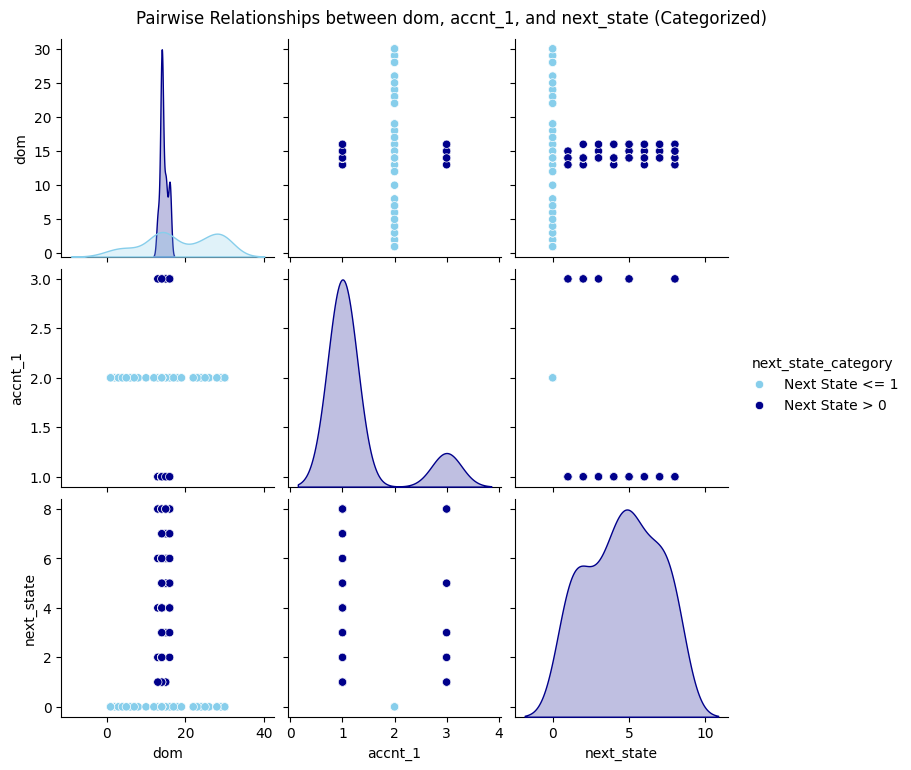

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a subset of the DataFrame with the relevant columns
plot_df = x[['dom', 'accnt_1', 'next_state']].copy() # Use .copy() to avoid SettingWithCopyWarning

# Create a new categorical column for coloring based on the condition
plot_df['next_state_category'] = plot_df['next_state'].apply(
    lambda val: 'Next State > 0' if val > 0 else 'Next State <= 1'
)

# Define a custom palette for clearer distinction
# Use a darker color for 'Next State > 2' and a lighter one for 'Next State <= 2'
custom_palette = {
    'Next State <= 1': 'skyblue',  # Lighter color
    'Next State > 0': 'darkblue'    # Darker, more distinctive tone
}

# Generate the pairplot
sns.pairplot(plot_df, hue='next_state_category', diag_kind='kde', palette=custom_palette)
plt.suptitle('Pairwise Relationships between dom, accnt_1, and next_state (Categorized)', y=1.02)
plt.show()

In [ ]:
#For supervised learning excercise only
y_supervised = x_supervised['next_state']
x_supervised = x_supervised.iloc[:, :6]
x_supervised.head()

,current_state,dom,accnt_1,accnt_2,accnt_3,accnt_4
70,0,14,3,0,0,0
73,0,14,1,0,0,0
77,3,14,1,0,0,0
78,4,14,1,0,0,0
544,0,14,1,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

# Split into train and test sets using the designated test proportion and global seed
x_train, x_test, y_train, y_test = train_test_split(
    x_supervised,
    y_supervised,
    test_size=TEST_PROPORTION,
    random_state=SEED
)

print(f"Training set shape: {x_train.shape}")
print(f"Test set shape: {x_test.shape}")

Training set shape: (161, 6)
Test set shape: (54, 6)


### Supervised Learning Pipeline for the DQN Architecture

Instead of updating model parameters through RL rewards and Q-value iteration, we will optimize the DQN neural network architecture using standard supervised learning (classification). We use the actual target action (`y_train`/`y_test`) as our supervised target labels.

In [ ]:
# We will explicitly update the global ACTIONS_DIM variable to 9 first.
ACTIONS_DIM = unique_user_actions.size

# Initialize a fresh DQN model instance with updated output dimension
supervised_dqn = DQN()

# Re-compile the model for multiclass classification using sparse categorical crossentropy
supervised_dqn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Fit the model using standard supervised training
history = supervised_dqn.fit(
    x_train,
    y_train,
    epochs=150,
    batch_size=35,
    validation_split=0.1,
    verbose=1
)

Epoch 1/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.0417 - loss: 3.6830 - val_accuracy: 0.3529 - val_loss: 1.7466
Epoch 2/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5069 - loss: 1.7812 - val_accuracy: 0.7647 - val_loss: 1.0312
Epoch 3/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5417 - loss: 1.7667 - val_accuracy: 0.7647 - val_loss: 0.9706
Epoch 4/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5417 - loss: 1.6720 - val_accuracy: 0.7647 - val_loss: 0.9584
Epoch 5/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5625 - loss: 1.6042 - val_accuracy: 0.7647 - val_loss: 1.0950
Epoch 6/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5694 - loss: 1.5894 - val_accuracy: 0.7647 - val_loss: 1.0385
Epoch 7/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5625 - loss: 1.4976 - val_accuracy: 0.7647 - val_loss: 1.0097
Epoch 8/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5625 - loss: 1.4430 - val_accuracy: 0.7647 - val_loss:

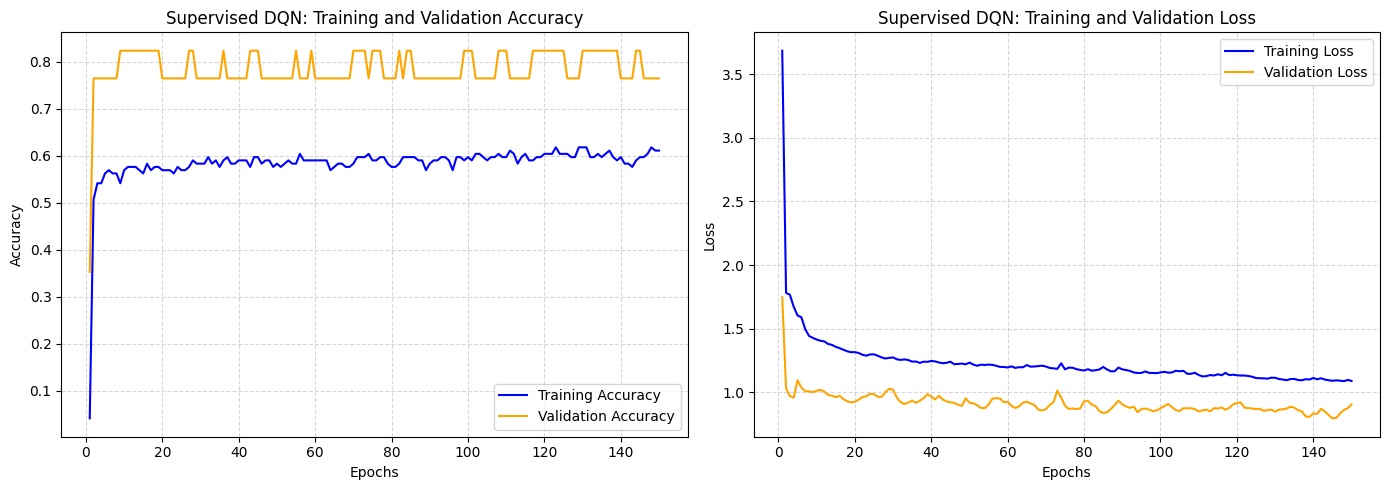

In [ ]:
import matplotlib.pyplot as plt

# Extract metrics from history of supervised_dqn
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Create plots
plt.figure(figsize=(14, 5))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange')
plt.title('Supervised DQN: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange')
plt.title('Supervised DQN: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Upgraded DQN Architecture with Dropout
We subclass `DQN` (or define a similar architecture) to insert `Dropout` layers after our dense layers. This acts as a regularizer during training to prevent the network from memorizing the highly-imbalanced training samples.

In [ ]:
supervised_dqn_dropout_unweighted = RegularizedDQN(dropout_rate=0.10)

supervised_dqn_dropout_unweighted.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

history_dropout_unweighted = supervised_dqn_dropout_unweighted.fit(
    x_train,
    y_train,
    epochs=150,
    batch_size=35,
    validation_split=0.1,
    verbose=1
)

Epoch 1/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.2361 - loss: 2.2272 - val_accuracy: 0.7647 - val_loss: 1.1063
Epoch 2/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5417 - loss: 1.8371 - val_accuracy: 0.7647 - val_loss: 1.0533
Epoch 3/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5347 - loss: 1.7242 - val_accuracy: 0.7647 - val_loss: 1.0228
Epoch 4/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5486 - loss: 1.6836 - val_accuracy: 0.7647 - val_loss: 1.1095
Epoch 5/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4931 - loss: 1.6414 - val_accuracy: 0.7647 - val_loss: 1.0919
Epoch 6/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5417 - loss: 1.5992 - val_accuracy: 0.7647 - val_loss: 1.0206
Epoch 7/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5486 - loss: 1.5675 - val_accuracy: 0.7647 - val_loss: 1.0160
Epoch 8/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5694 - loss: 1.4896 - val_accuracy: 0.7647 - val_loss:

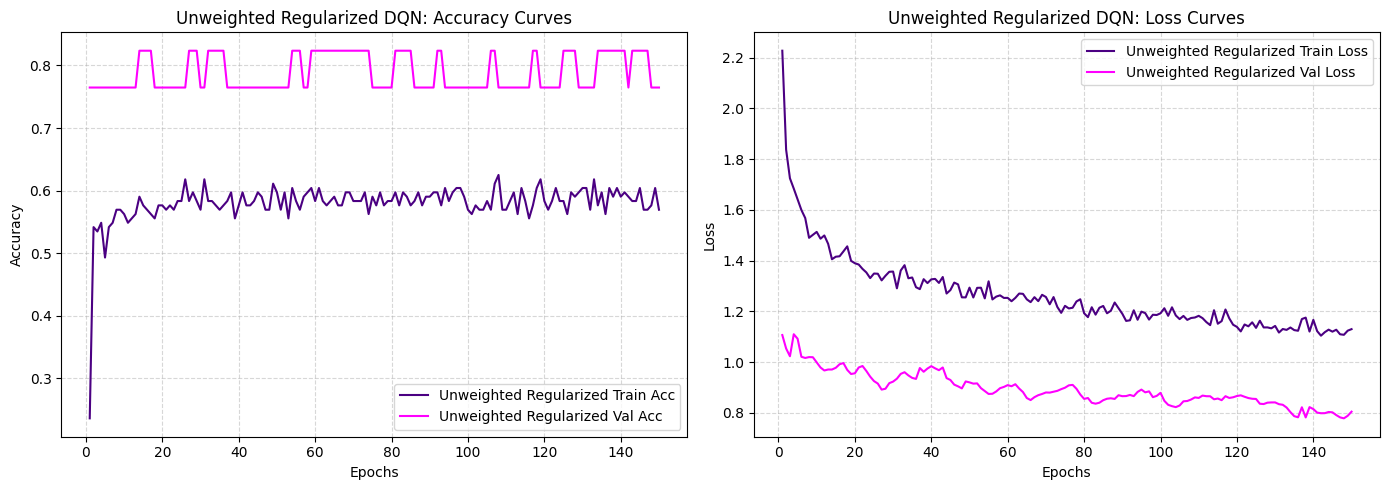

In [ ]:
import matplotlib.pyplot as plt

acc_unweighted = history_dropout_unweighted.history['accuracy']
val_acc_unweighted = history_dropout_unweighted.history['val_accuracy']
loss_unweighted = history_dropout_unweighted.history['loss']
val_loss_unweighted = history_dropout_unweighted.history['val_loss']
epochs_range = range(1, len(acc_unweighted) + 1)

plt.figure(figsize=(14, 5))

# Subplot 1: Accuracy curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_unweighted, label='Unweighted Regularized Train Acc', color='indigo')
plt.plot(epochs_range, val_acc_unweighted, label='Unweighted Regularized Val Acc', color='magenta')
plt.title('Unweighted Regularized DQN: Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Loss curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_unweighted, label='Unweighted Regularized Train Loss', color='indigo')
plt.plot(epochs_range, val_loss_unweighted, label='Unweighted Regularized Val Loss', color='magenta')
plt.title('Unweighted Regularized DQN: Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_accuracy = supervised_dqn.evaluate(x_test, y_test, verbose=0)
print(f"Supervised DQN Test Loss: {test_loss:.4f}")
print(f"Supervised DQN Test Accuracy: {test_accuracy * 100:.2f}%")

Supervised DQN Test Loss: 0.7444
Supervised DQN Test Accuracy: 77.78%


In [ ]:
reg_test_loss, reg_test_accuracy = supervised_dqn_dropout_unweighted.evaluate(x_test, y_test, verbose=0)
print(f"Regularized DQN (Unweighted) Test Loss: {reg_test_loss:.4f}")
print(f"Regularized DQN (Unweighted) Test Accuracy: {reg_test_accuracy * 100:.2f}%")

Regularized DQN (Unweighted) Test Loss: 0.7209
Regularized DQN (Unweighted) Test Accuracy: 74.07%


## Unsupervised pipeline

In [ ]:
#Reward weights map
reward_weights = {"match_transactional_weight": 5, "non_match_transactional_weight": 2, "match_non_transactional_weight": 1, "non_match_weight": -1}

In [ ]:
# Instantiate a new SignatureRegularizedDQN model compiled with MSE for RL target regression
sig_dqn_test_model = SignatureRegularizedDQN(dropout_rate=0.10)
sig_dqn_test_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.MeanSquaredError(),
    metrics=['mae']
)

In [ ]:
# Run the reinforcement learning train_DQ loop with our model and the x DataFrame
cumulative_reward, episode_reward, mae, predictions = train_DQ(
    data_frame=x,
    model=sig_dqn_test_model,
    reward_weights=reward_weights,
    gamma=0.005,
    epsilon=0.65,
    epsilon_decay=0.1,
    batch_size=30,
    N_Episodes=250
)

print(f"\nTest Complete!")
print(f"Cumulative Reward obtained: {cumulative_reward}")
print(f"Average Mean Absolute Error across episodes: {np.mean(mae):.4f}")

Running environment for a total of 179 episodes/user-sessions
-----------------
current_state: [[ 0. 23.  2.  0.  0.  0.]]
next_state: [[ 0. 23.  2.  0.  0.  0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
Qs: [ 0.30492538  2.304446    2.3093576  -0.18576409  0.44302365  1.890163
 -0.39698264 -2.1949644  -2.3924563 ]
Predicted State New: 1.0
False
Reward: -1.0
MAE: 1.0
-----------------
current_state: [[ 0. 28.  2.  0.  0.  0.]]
next_state: [[ 0. 28.  2.  0.  0.  0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Qs: [ 0.37401617  2.8164005   2.755234   -0.21774095  0.5539968   2.3566666
 -0.5050844  -2.6535761  -2.8073084 ]
Predicted State New: 1.0
False
Reward: -1.0
MAE: 1.0
Finished episode
-----------------
current_state: [[ 0. 30.  2.  0.  0.  0.]]
next_state: [[ 0. 30.  2.  0.  0.  0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Qs: [ 0.40254736  3.02073     2.9336214  -0.22764325  0.5969569   2.5445127
 -0.551571   -2.8363967  -2.9723601 ]
Predicted State New: 1.0
False
Reward: -1.0
MAE: 1.0
Fin

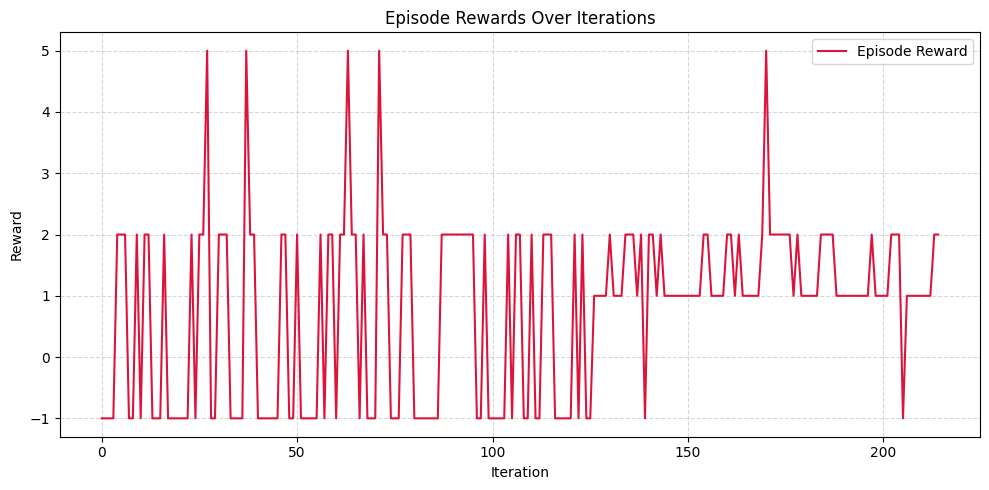

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Convert episode_reward list to a numpy array for easy handling
rewards_array = np.array(episode_reward)
predictions = np.array(predictions)

# Perform a simple plot of episode rewards over the iterations
plt.figure(figsize=(10, 5))
plt.plot(np.arange(len(rewards_array)), rewards_array, color='crimson', linewidth=1.5, label='Episode Reward')
plt.title('Episode Rewards Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Reward')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Fine tunning the Reinforcement DQN Network with transfer learning weights from supervised network

In [ ]:
# Save weights from the supervised model with dropout
supervised_weights_path = '/content/supervised_dqn_dropout.weights.h5'
supervised_dqn_dropout_unweighted.save_weights(supervised_weights_path)
print(f"Supervised weights successfully saved to {supervised_weights_path}")

# Redefine sig_dqn_test_model using these pre-trained weights
sig_dqn_test_model = SignatureRegularizedDQN(dropout_rate=0.10)

# Build the variables of the model by calling it on a dummy input
sig_dqn_test_model(np.zeros((1, FEATURE_DIM), dtype=np.float32))

# Load the weights from the supervised step
sig_dqn_test_model.load_weights(supervised_weights_path)
print("Weights loaded successfully into sig_dqn_test_model!")

# Compile the model with MSE loss for RL regression
sig_dqn_test_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.MeanSquaredError(),
    metrics=['mae']
)

Supervised weights successfully saved to /content/supervised_dqn_dropout.weights.h5
Weights loaded successfully into sig_dqn_test_model!


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Execute reinforcement learning training loop with the pre-initialized model
cumulative_reward, episode_reward, mae, predictions = train_DQ(
    data_frame=x,
    model=sig_dqn_test_model,
    reward_weights=reward_weights,
    gamma=0.005,
    epsilon=0.65,
    epsilon_decay=0.1,
    batch_size=30,
    N_Episodes=250
)

print(f"\nTraining Complete with pre-trained weights!")
print(f"Cumulative Reward obtained: {cumulative_reward}")
print(f"Average Mean Absolute Error across episodes: {np.mean(mae):.4f}")

Running environment for a total of 179 episodes/user-sessions
-----------------
current_state: [[ 0. 29.  2.  0.  0.  0.]]
next_state: [[ 0. 29.  2.  0.  0.  0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Qs: [ 4.653496  -2.1718984 -0.9478295 -2.1124322 -0.7769151 -0.6551657
 -4.1487308 -0.8489586 -0.8719685]
Predicted State New: 1.0
False
Reward: -1.0
MAE: 1.0
-----------------
current_state: [[ 0. 14.  2.  0.  0.  0.]]
next_state: [[ 0. 14.  2.  0.  0.  0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Qs: [ 2.8335993  -0.79149115  0.22693034 -0.5128606  -1.3273574  -0.24103169
 -2.38767    -1.5581423  -0.6865414 ]
Predicted State New: 0.0
False
Reward: 1.0
MAE: 0.0
-----------------
current_state: [[ 3. 14.  1.  0.  0.  0.]]
next_state: [[ 6. 14.  1.  0.  0.  0.]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Qs: [-2.4908597  -0.29126617 -0.23495054 -0.1827981   0.66069627  0.49100947
  1.0654697   0.77605844  0.32597867]
Predicted State New: 6.0
False
Reward: 5.0
MAE: 0.0
-----------------
current_st

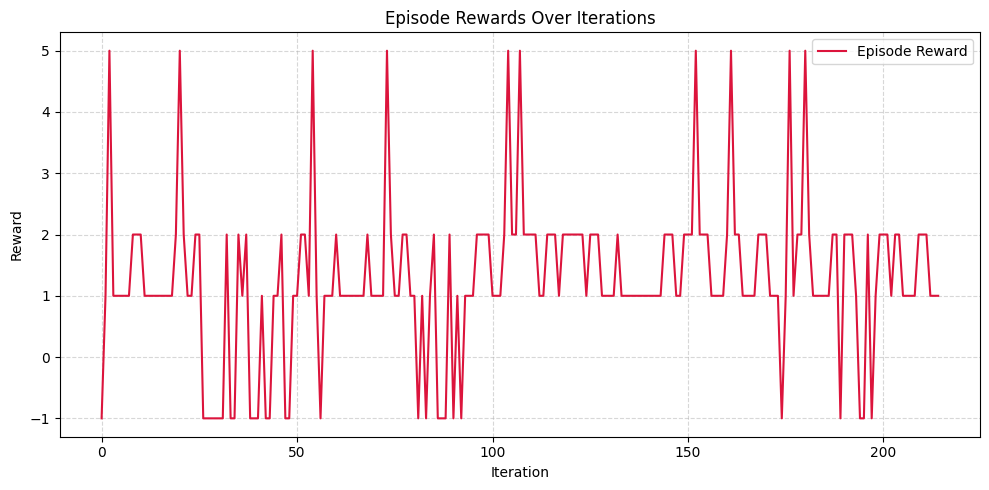

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Convert episode_reward list to a numpy array for easy handling
rewards_array = np.array(episode_reward)
predictions = np.array(predictions)

# Perform a simple plot of episode rewards over the iterations
plt.figure(figsize=(10, 5))
plt.plot(np.arange(len(rewards_array)), rewards_array, color='crimson', linewidth=1.5, label='Episode Reward')
plt.title('Episode Rewards Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Reward')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
sig_dqn_test_model.predict(np.arange(6).reshape(1, -1))[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


array([ 4.0717893 , -0.04934147, -0.6064439 , -0.94546014, -2.616423  ,
       -1.111135  , -2.2599585 , -1.9842832 , -2.1474874 ], dtype=float32)

In [ ]:
predictions[predictions>-1]

array([0., 0., 6., 0., 0., 0., 0., 0., 7., 5., 4., 0., 0., 0., 0., 0., 0.,
       0., 0., 4., 6., 5., 0., 0., 8., 7., 0., 0., 0., 0., 0., 0., 5., 0.,
       0., 5., 0., 3., 0., 0., 0., 0., 0., 0., 0., 0., 5., 0., 0., 0., 0.,
       2., 5., 0., 4., 0., 0., 0., 0., 0., 7., 0., 0., 0., 0., 0., 0., 0.,
       2., 0., 0., 0., 0., 4., 1., 0., 0., 2., 7., 0., 0., 0., 0., 0., 0.,
       3., 0., 0., 0., 7., 0., 0., 0., 0., 0., 0., 8., 8., 1., 2., 0., 0.,
       0., 5., 6., 7., 4., 6., 8., 1., 6., 8., 0., 0., 7., 3., 8., 0., 3.,
       4., 1., 2., 8., 1., 0., 4., 5., 3., 0., 0., 0., 0., 1., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 1., 8., 5., 0., 0., 5., 7., 1., 6.,
       2., 8., 4., 0., 0., 0., 0., 2., 6., 3., 7., 0., 0., 0., 0., 4., 5.,
       5., 0., 0., 0., 0., 0., 6., 0., 1., 8., 6., 7., 0., 0., 0., 0., 0.,
       7., 4., 0., 8., 2., 1., 0., 0., 0., 1., 0., 0., 5., 3., 2., 0., 4.,
       4., 0., 0., 0., 0., 5., 1., 5., 0., 0., 0.])

In [ ]:
x[x['next_state']>-1].iloc[:, 6].to_numpy()

array([0, 0, 6, 0, 1, 6, 2, 8, 4, 8, 6, 7, 0, 0, 3, 0, 0, 5, 4, 5, 4, 5,
       0, 0, 0, 6, 0, 0, 5, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 8, 1, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 2, 8, 1, 3, 7, 0, 0, 4, 5, 0, 0, 2, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 4, 6, 8, 0, 0, 0, 0, 0, 0, 0, 0, 3,
       0, 0, 5, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 0, 4, 6, 5, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 2, 0,
       0, 0, 0, 0, 1, 0, 0, 7, 4, 0, 0, 0, 0, 2, 2, 5, 0, 1, 5, 7, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 5, 6, 8, 0, 0, 0, 0, 3, 4, 0, 7, 0, 0,
       0, 4, 1, 8, 7, 1, 0, 8, 5, 6, 7, 0, 5, 7, 0, 7, 3, 8, 8, 0, 0, 0,
       4, 5, 3, 0, 5, 2, 7, 0, 0, 5, 0, 0, 8, 0, 4, 0, 0])

In [ ]:
np.array(predictions)[np.array(episode_reward)>1]

array([6., 7., 5., 4., 4., 6., 5., 8., 7., 5., 5., 3., 5., 2., 5., 4., 7.,
       2., 4., 1., 2., 7., 3., 7., 8., 8., 1., 2., 5., 6., 7., 4., 6., 8.,
       1., 6., 8., 7., 3., 8., 3., 4., 1., 2., 8., 1., 4., 5., 3., 1., 1.,
       8., 5., 5., 7., 1., 6., 2., 8., 4., 2., 6., 3., 7., 4., 5., 5., 6.,
       1., 8., 6., 7., 7., 4., 8., 2., 1., 1., 5., 3., 2., 4., 4., 5., 1.,
       5.])

### Exporting the DQN Model to LiteRT (TFLite)

To bypass the untracked resource variable error during conversion, we can generate a clean concrete function directly from our model's `call` method (using standard tensor inputs) and pass it to the converter. This avoids serializing internal random seed state variables that are not tracked in the subclassed architecture.

In [ ]:
import tensorflow as tf

# 1. Define a clean prediction function using the model's call method
@tf.function(input_signature=[tf.TensorSpec(shape=[None, FEATURE_DIM], dtype=tf.float32, name='app_state')])
def inference_function(app_state):
    return sig_dqn_test_model(app_state, training=False)

# 2. Extract the concrete function
concrete_func = inference_function.get_concrete_function()

# 3. Initialize converter from the concrete function
converter = tf.lite.TFLiteConverter.from_concrete_functions([concrete_func], sig_dqn_test_model)

# Enable TensorFlow Select Ops just in case
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]
converter.experimental_enable_resource_variables = True

# 4. Convert and save
tflite_model = converter.convert()
tflite_model_path = "sig_dqn_model.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print(f"Success! Model converted and saved to '{tflite_model_path}'")

Success! Model converted and saved to 'sig_dqn_model.tflite'


In [ ]:
!ls

Banking-Dataset  sig_dqn_model.tflite
sample_data	 supervised_dqn_dropout.weights.h5


In [ ]:
import numpy as np
import tensorflow as tf
from ai_edge_litert.interpreter import Interpreter

# 1. Instantiate the SignatureRegularizedDQN model and load the weights
test_model = SignatureRegularizedDQN(dropout_rate=0.10)

# Call on dummy input to build variables before loading weights
test_model(np.zeros((1, FEATURE_DIM), dtype=np.float32))

# Load pre-trained weights
weights_path = '/content/supervised_dqn_dropout.weights.h5'
test_model.load_weights(weights_path)
print("Keras Model successfully instantiated and weights loaded.")

# 2. Load the converted LiteRT model
tflite_model_path = "sig_dqn_model.tflite"
interpreter = Interpreter(model_path=tflite_model_path)
interpreter.allocate_tensors()
print("LiteRT Model successfully loaded.")

Keras Model successfully instantiated and weights loaded.
LiteRT Model successfully loaded.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
import numpy as np
import tensorflow as tf
from ai_edge_litert.interpreter import Interpreter

# 1. Instantiate Keras Model and load pre-trained weights
keras_model = SignatureRegularizedDQN(dropout_rate=0.10)
keras_model(np.zeros((1, FEATURE_DIM), dtype=np.float32)) # build variables
weights_path = '/content/supervised_dqn_dropout.weights.h5'
keras_model.load_weights(weights_path)
print("Keras Model successfully loaded with weights.")

# 2. Export this exact weighted model to LiteRT
@tf.function(input_signature=[tf.TensorSpec(shape=[None, FEATURE_DIM], dtype=tf.float32, name='app_state')])
def inference_function(app_state):
    return keras_model(app_state, training=False)

concrete_func = inference_function.get_concrete_function()
converter = tf.lite.TFLiteConverter.from_concrete_functions([concrete_func], keras_model)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]
converter.experimental_enable_resource_variables = True

tflite_model = converter.convert()
tflite_model_path = "sig_dqn_model.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)
print("LiteRT Model successfully exported with current weights.")

# 3. Load the newly exported LiteRT model into a fresh interpreter
fresh_interpreter = Interpreter(model_path=tflite_model_path)
fresh_interpreter.allocate_tensors()

# Get input/output details
input_details = fresh_interpreter.get_input_details()
output_details = fresh_interpreter.get_output_details()

# Run prediction on both Keras and LiteRT
sample_input = np.array([[0.0, 15.0, 3.0, 0.0, 0.0, 0.0]], dtype=np.float32)
keras_prediction = keras_model(sample_input, training=False).numpy()

fresh_interpreter.set_tensor(input_details[0]['index'], sample_input)
fresh_interpreter.invoke()
litert_prediction = fresh_interpreter.get_tensor(output_details[0]['index'])

print("\n--- Verification Results ---")
print(f"Sample Input: {sample_input}")
print(f"Keras Model Prediction:   {keras_prediction[0]}")
print(f"LiteRT Model Prediction:  {litert_prediction[0]}")

# Verify outputs match within float precision tolerance
np.testing.assert_allclose(keras_prediction, litert_prediction, rtol=1e-5, atol=1e-5)
print("\nSuccess! Predictions are identical within a margin of 1e-5.")

Keras Model successfully loaded with weights.
LiteRT Model successfully exported with current weights.

--- Verification Results ---
Sample Input: [[ 0. 15.  3.  0.  0.  0.]]
Keras Model Prediction:   [ 2.6883063  -0.5197358   0.90448904 -0.14900523 -1.9478354  -0.09094803
 -2.4037783  -2.1530566  -0.74357533]
LiteRT Model Prediction:  [ 2.6883063  -0.51973575  0.9044892  -0.14900509 -1.9478353  -0.0909479
 -2.4037783  -2.1530566  -0.7435755 ]

Success! Predictions are identical within a margin of 1e-5.


### Detailed Performance Analysis: Baseline vs. Pre-trained DQN

When we analyze the reinforcement learning execution metrics, we observe a highly interesting paradox:
- **Baseline DQN (From Scratch):** Cumulative Reward = **79.0**, Avg MAE = **0.1583**
- **Pre-trained DQN (Transfer Learning):** Cumulative Reward = **-41.0**, Avg MAE = **0.1370**

#### Why did the Pre-trained model yield a lower Cumulative Reward?

1. **The Nature of the Supervised Initializer:**
   The pre-trained weights were obtained by training the DQN as a standard classifier using standard supervised learning. In our unbalanced dataset, non-transactional actions ('Dashboard') represent the vast majority of the samples. Therefore, the supervised network learned to heavily favor predicting the dominant class to minimize cross-entropy loss.

2. **The Exploration-Exploitation Dilemma and Policy Entrenchment:**
   Because the weights were pre-trained, the Q-network started the RL phase with highly established, low-entropy predictions (biases). Instead of exploring the action space homogeneously, the pre-trained agent strongly preferred its pre-established "safe" predictions. This trapped the agent in sub-optimal local minima where it continuously selected incorrect non-transactional actions, incurring persistent penalties (`non_match_weight = -1`), rather than finding the highly rewarded transactional actions.

3. **Why is the MAE lower then?**
   Mean Absolute Error (MAE) measures the average distance between predicted indices and true target indices. Since the action maps are contiguous and dominated by non-transactional labels, predicting safe values near the center of the label mapping yields a lower overall numerical deviation (MAE). However, in reinforcement learning, rewards are binary/sparse: a close miss (`MAE = 1`) gets the same strict penalty as a far miss (`MAE = 8`). MAE does not correlate linearly with the step-reward matrix defined in `compute_rewards`.

In [ ]:
from google.colab import files
files.download(tflite_model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>